# Example 3: Deep Formulas

The orignal Kolmogorov-Arnold theorem says that it suffices to have 2-Layer function composition (inner and outer functions), but the functions might be non-smooth or even fractal. We generalize KA representation to arbitrary depths. An example a 2-Layer KAN (with smooth activations) is unable to do is: $f(x_1,x_2,x_3,x_4)={\rm exp}({\rm sin}(x_1^2+x_2^2)+{\rm sin}(x_3^2+x_4^2))$, which requires at least 3-Layer KANs.

### Three-layer KAN

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune, refine
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
# scale_sp_fan_in=False: each curve starts at full strength, as in pykan up to 0.2.7 (0.2.8 divides it by the square
# root of the layer's number of inputs, and this network then trains far worse)
model = KANNetwork([4, 2, 1, 1], grid=3, k=3, seed=1, device=device, scale_sp_fan_in=False)
f = lambda x: torch.exp((torch.sin(torch.pi*(x[:,[0]]**2+x[:,[1]]**2))+torch.sin(torch.pi*(x[:,[2]]**2+x[:,[3]]**2)))/2)
train, test = create_dataset(f, n_var=4, train_num=3000, device=device)

# train the model
history = fit(model, train, test, steps=20, lamb=0.002, lamb_entropy=2.)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.02453999583830923 test RMSE 0.02464834219094967


In [2]:
model = prune(model, train['x'], edge_th=1e-2)

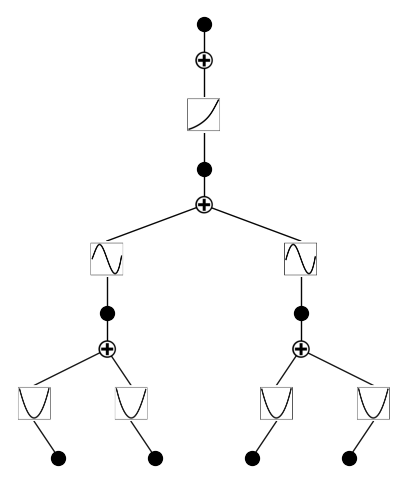

In [3]:
plot(model, train['x']);

In [4]:
grids = [3,5,10,20,50]
#grids = [5]

train_rmse = []
test_rmse = []

for i in range(len(grids)):
    model = refine(model, grids[i], train['x'])
    history = fit(model, train, test, steps=50, stop_grid_update_step=20)
    train_rmse.append(history['train/y'][-1] ** 0.5)
    test_rmse.append(history['val/y'][-1] ** 0.5)

Author's note: The scaling isn't optimal. Possibly because of updates on curve2coef, to be investigated. 

[0.009555108887431787, 0.004209671397988396, 0.0015642769978290686, 0.0003938815637388788, 3.8013126523498225e-05]
[0.009476290790862228, 0.004101830951599217, 0.0015909151384316635, 0.0003760819571450625, 4.134643834278427e-05]


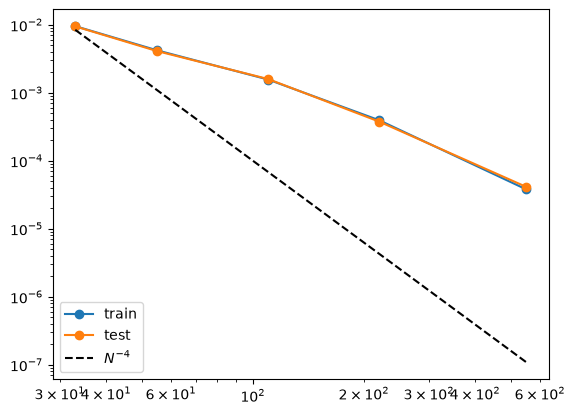

In [5]:
import numpy as np
import matplotlib.pyplot as plt

n_params = np.array(grids) * (4*2+2*1+1*1)
plt.plot(n_params, train_rmse, marker="o")
plt.plot(n_params, test_rmse, marker="o")
plt.plot(n_params, 10000*n_params**(-4.), color="black", ls="--")
plt.legend(['train', 'test', r'$N^{-4}$'], loc="lower left")
plt.xscale('log')
plt.yscale('log')
print(train_rmse)
print(test_rmse)

### Two-layer KAN

Now we show that a 2 two-layer KAN performs much worse for this task

train RMSE 0.06467971563724514 test RMSE 0.06694157888102283


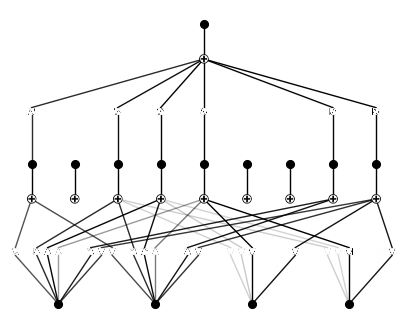

In [6]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.viz import plot

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
# scale_sp_fan_in=False: each curve starts at full strength, as in pykan up to 0.2.7 (0.2.8 divides it by the square
# root of the layer's number of inputs, and this network then trains far worse)
model = KANNetwork([4, 9, 1], grid=3, k=3, seed=0, scale_sp_fan_in=False)
f = lambda x: torch.exp((torch.sin(torch.pi*(x[:,[0]]**2+x[:,[1]]**2))+torch.sin(torch.pi*(x[:,[2]]**2+x[:,[3]]**2)))/2)
train, test = create_dataset(f, n_var=4, train_num=3000)

# train the model
history = fit(model, train, test, steps=20, lamb=0.002, lamb_entropy=2.)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
plot(model, train['x'], beta=10);

In [7]:
from xkan.interp import refine

grids = [3,5,10,20,50]

train_rmse = []
test_rmse = []

for i in range(len(grids)):
    model = refine(model, grids[i], train['x'])
    history = fit(model, train, test, steps=50, stop_grid_update_step=30)
    train_rmse.append(history['train/y'][-1] ** 0.5)
    test_rmse.append(history['val/y'][-1] ** 0.5)

[0.023560543731977645, 0.008516902625413256, 0.004312798694472866, 0.0027048252287726073, 0.00111091126059114]
[0.026433902244718192, 0.011024884279042768, 0.00686755886742864, 0.008631465524130978, 0.009128248939954009]


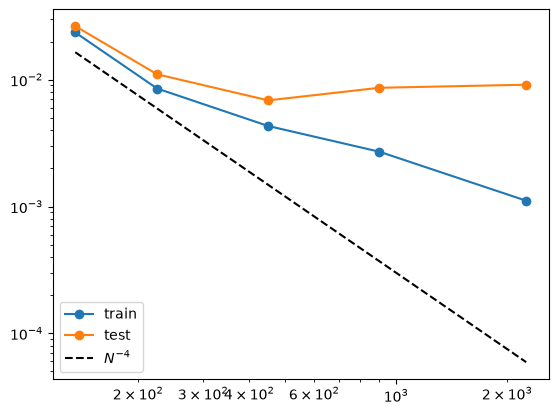

In [8]:
import numpy as np
import matplotlib.pyplot as plt

n_params = np.array(grids) * (4*9+9*1)
plt.plot(n_params, train_rmse, marker="o")
plt.plot(n_params, test_rmse, marker="o")
plt.plot(n_params, 300*n_params**(-2.), color="black", ls="--")
plt.legend(['train', 'test', r'$N^{-4}$'], loc="lower left")
plt.xscale('log')
plt.yscale('log')
print(train_rmse)
print(test_rmse)